# 06 — Decisões, problemas e perguntas

Atualiza `Relatórios do Projeto/06_DECISOES_PROBLEMAS_PERGUNTAS.md` (última edição em 02/11/2026). Mostra o que
foi decidido e por quem, o que ficou para trás, o que está em aberto e quem decide, os problemas conhecidos e
as perguntas.

A fonte de cada decisão é o `abandono-escolar/docs/DECISOES.md`. Este notebook não decide nada.

## O que mudou desde o relatório 06

| Tema | Relatório 06 | Agora (10/11/2026) |
|---|---|---|
| Decisões | lista D1–D16 do grupo e da análise do v1 | cada uma com o estado de hoje: vigente, feita, substituída pelo protocolo, aguardando decisão ou não implementada (§2). As decisões de desenho são as do orientador (D1–D7, D10) e as do protocolo de 02/11 |
| Problemas | P001–P007, P019–P020, P023 e M001–M004 | `problemas.csv` com P001–P018 e P026; linhas P006 (correção), P019–P023 e P027 propostas e não coladas; M001–M004 com estado (§7) |
| Perguntas | Q1–Q10 em aberto | cada uma respondida, respondida em parte ou ainda aberta (§8); perguntas novas (§9) |
| Divergências | — | **quatro frases dos documentos oficiais que a evidência contradiz** (§5), para a pesquisadora decidir |

In [1]:
import sys
from pathlib import Path

AQUI = Path.cwd()                                  # o notebook roda de Dados-do-Projeto/Contexto do Projeto
if not (AQUI / "gerar_tabelas.py").exists():
    raise FileNotFoundError(f"Abra este notebook de dentro de Dados-do-Projeto/Contexto do Projeto (pasta atual: {AQUI})")
DADOS_DO_PROJETO = AQUI.parent
OFICIAL = DADOS_DO_PROJETO / "abandono-escolar"    # junction para Pmonkey/abandono-escolar
GUSTAVO = DADOS_DO_PROJETO / "gustavo"
sys.path.insert(0, str(OFICIAL))
sys.path.insert(0, str(AQUI))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display

import desenho as D
from src import figuras as F

print(F.conferir_ambiente(OFICIAL / "requirements.txt"))
F.aplicar_estilo()
pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 30)
TABELAS = AQUI / "tabelas"                         # python gerar_tabelas.py
FIGURAS = AQUI / "figuras"


def figura_existente(caminho, largura=820):
    """Mostra uma figura gerada por outro notebook (não a recalcula)."""
    F.exigir({caminho.name: caminho}, como_gerar="executar o notebook que a gera (ver a legenda)")
    display(Image(filename=str(caminho), width=largura))

{'pandas': '3.0.5', 'numpy': '2.5.3', 'matplotlib': '3.11.1'}


In [2]:
REG = AQUI / "registros"
ENTRADAS = {
    "decisoes": REG / "decisoes_doc06.csv",                  # escrito à mão, com fonte (README)
    "perguntas": REG / "perguntas_doc06.csv",                # idem
    "problemas": TABELAS / "problemas_todos.csv",            # gerar_tabelas.py (planilha oficial + registros)
    "extras": REG / "problemas_fora_do_csv.csv",             # escrito à mão: linhas propostas e M001–M004
    "planilha": OFICIAL / "docs" / "problemas.csv",          # mantida à mão pela pesquisadora
    "tempo": TABELAS / "linha_do_tempo_decisoes.csv",        # gerar_tabelas.py, a partir do DECISOES.md
}
F.exigir(ENTRADAS, como_gerar='python "Contexto do Projeto/gerar_tabelas.py"')
t = {k: pd.read_csv(v, keep_default_na=False) for k, v in ENTRADAS.items()}
pd.set_option("display.max_colwidth", 200)

## 1. Três numerações "D" que colidem

Quem lê "D8" precisa saber de qual lista é:

| Lista | Onde | O que numera | Exemplo de colisão |
|---|---|---|---|
| **metodologia D1–D11** | `docs/metodologia_variaveis.md` §0; `DECISOES.md` (D1–D7 datadas de 17/09) | decisões de desenho do orientador (D1–D7, D10) e propostas (D8, D9, D11) | **D8** = trazer indígena, localização diferenciada e matrículas (proposta) |
| **doc 06 D1–D16** | `Relatórios do Projeto/06` | decisões do grupo e da análise dos notebooks v1 | **D8** = Pé-de-Meia como período pré/pós-2024 |
| **VISAO D-A …** | `Dados-do-Projeto/VISAO_GERAL_DO_PROJETO.md` §3.1 | decisões pedidas ao orientador em 02/11 | **D-A** = juntar TDI/ATU/IED à base estendida (feito só em memória) |

**Equivalências:**

| doc 06 | metodologia | DECISOES.md |
|---|---|---|
| D5 (AF e EM separados) | D2 | D2, 17/09 |
| D6 (desfecho em *t*+1) | D4 | D4, 17/09 |
| D11 (indígena, localização diferenciada) | D8 (proposta) | — |
| D12 (multisseriada) | D9 (proposta) | — |
| D13 (IED 2019–2020 e HAD) | — | P019 (linha proposta) |

Nestes notebooks, "D*n*" sem qualificação é a numeração da **metodologia**. A do doc 06 aparece como "doc 06,
D*n*".

## 2. As 16 decisões do doc 06, hoje

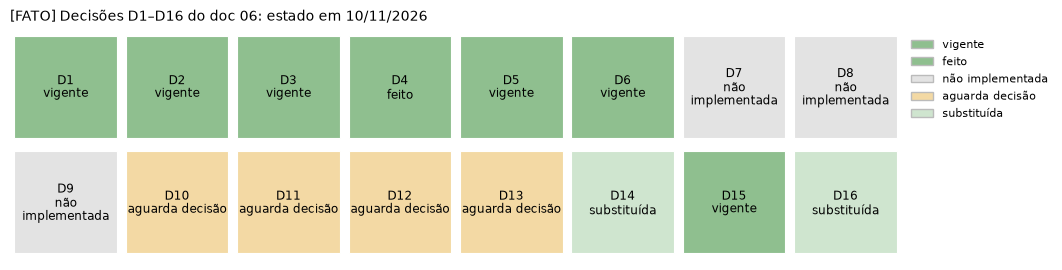

,decisao,estado,hoje,fonte
id,,,,
D1,Base dos Dados não é fonte do desfecho (falta o tx_rend),vigente,o desfecho vem do tx_rend do INEP,Relatórios do Projeto/02 §6
D2,Fonte do desfecho: tx_rend do INEP,vigente,"harmonizado pelo rótulo humano: 2 gerações de layout na base oficial, 3 no gustavo/",metodologia §4.2; síntese §2
D3,"A v1.0 do orientador é referência, não substitui o código",vigente,dependência externa documentada; a base oficial é a regerada por código,DECISOES.md 2026-09-30
D4,src/base_longitudinal.py reproduz a v1.0,feito,mesmas 6.054 linhas; 49 colunas idênticas e 8 na tolerância de 1e-9,"CLAUDE.md §8, critérios 1–4"
D5,Dois conjuntos: AF e EM,vigente,"é a D2 da metodologia (orientador, 17/09)",DECISOES.md D2
D6,Desfecho: abandono em t+1,vigente,é a D4 da metodologia,DECISOES.md D4
D7,INSE só para comparar grupos,não implementada,INSE nunca carregado,síntese §5.5
D8,Pé-de-Meia como período pré/pós-2024,não implementada,variável não construída,síntese §5.5
D9,Cuidado com vazamento do Pé-de-Meia,não implementada,sem objeto enquanto a variável não existir,—


In [3]:
d = t["decisoes"]
fig, ax = plt.subplots(figsize=(11.5, 3.0))
D.grade_estados(ax, d["id"], d["estado"], colunas=8, tamanho=8.5)
F.titulo(ax, "Decisões D1–D16 do doc 06: estado em 10/11/2026", "FATO")
F.salvar(fig, FIGURAS, "06_decisoes_doc06")
plt.show()
d.set_index("id")[["decisao", "estado", "hoje", "fonte"]]

## 3. As decisões vigentes

As decisões que valem hoje, com a origem de cada uma (síntese §6.1):

| Decisão | Quem decidiu | Estado |
|---|---|---|
| Escola-ano, chave `ANO + CO_ENTIDADE` (D1) | orientador, 17/09 | implementado; chave única testada |
| Dois painéis, AF e EM (D2) | orientador | implementado |
| Universo: públicas com taxa na etapa (D3) | orientador | implementado; tirar as escolas só de infantil (P017) é proposta |
| Desfecho: abandono da etapa em *t*+1 (D4) | orientador | implementado; limiar de "alto risco" não fixado |
| TDI é preditor (D5) | orientador | implementado |
| 2020–2021 ficam, com S1–S4 (D6) | orientador | ficam; S1–S4 não rodadas |
| 2024→2025 é o teste bloqueado (D7) | orientador | nenhum modelo do protocolo avaliado nela; ver §5, divergência 1 |
| Baselines antes de qualquer modelo (D10) | orientador | B0, B1, B1R, B1R_lag, B2; B3 só como Ridge; B4 não |
| Cada modelo só vê a sua etapa (doc 06, D15) | grupo | vigente, com a exceção do IED_FUN no AF |
| Nunca as três taxas juntas; IED só N1..N5; importância só por grupo (P026) | pesquisadora, 02/11 | implementado e testado |
| Cenário B como principal; A como teto | pesquisadora, 02/11 | implementado |
| Variação defasada no Cenário B | pesquisadora, 02/11 | implementado e testado |
| B1R_lag é a barra; B1R é limite otimista | pesquisadora, 02/11 | implementado; ver §5, divergência 2 |
| Famílias declaradas antes; Holm; K primário 10% e 20% | pesquisadora, 02/11 | aplicado no 02d |
| Infraestrutura fora do modelo, mantida como estratificação | pesquisadora, 02/11 | registrado; estratificação ainda não feita |
| Objetivo: identificar a informação com sinal; previsão como instrumento | pesquisadora, 02/11 | vigente **sem a consulta ao orientador que o §6 exige** (falha de processo registrada) |
| Fase 3 (variáveis novas) suspensa | pesquisadora, 02/11 | vigente |

## 4. O que foi revertido ou reaberto

| Antes | Depois | Por quê |
|---|---|---|
| comparar três famílias (RR, nacional, transferência); TDI como 2º desfecho | desenho atual (D1–D11) | decisão do orientador, 17/09 |
| cópia organizada dos zips em `interim/` | extração direta | duplicatas bit a bit (1,8 GB) |
| teto de 10–20 preditores | catálogo completo | pedido da pesquisadora |
| IIE com pesos fixos de 2019 (`zref19`, `prop`) | `zano`, PC1 por ano | `zref19` usa dado futuro nas dobras antes de 2019 |
| IDA e IDP só com todos os itens | itens disponíveis em cada ano | manter as definições do artigo de 2012 em diante |
| "1ª coluna não nula" no Censo | "1ª coluna coletada no Brasil, senão NaN" | colunas mantidas no layout sem coleta |
| B1R como barra | B1R_lag como barra | o abandono de *t* não existe no início de *t*+1 |
| previsão como fim | sinal por bloco; previsão como instrumento | decisão da pesquisadora, sem consulta ao orientador |
| `DELTA1` no Cenário B | variação defasada | DELTA1 + lag reconstrói o abandono de *t* |
| bloco 2 "adotado" (pontual) | indeterminado, depois nulo | bootstrap e Holm |
| grupo de permutação TDI/ATU | TDI e ATU separados | o ATU não tem sinal |
| corrigir os notebooks v1 (doc 06, D16) | substituídos pelo protocolo | — |

## 5. Divergências encontradas ao preparar estes notebooks (10/11/2026)

Quatro frases dos documentos oficiais não batem com a evidência do próprio projeto. As três primeiras mudam o
que a pesquisa afirma, e por isso **não foram corrigidas nos documentos**: o `CLAUDE.md` §6 manda parar e
perguntar. A correção proposta é só uma sugestão; a decisão é da pesquisadora, ouvido o orientador quando
indicado.

| # | Onde está | O que diz | O que a evidência mostra | Correção proposta | Quem decide |
|---|---|---|---|---|---|
| 1 | `CLAUDE.md` §6 ("Estado da D7"); metodologia §7.1; síntese §5.3 e §6.1 | a transição 2024→2025 "nunca foi usada para avaliar ou selecionar modelo" | o smoke test (sorteio dentro de ANO_ALVO = 2025), o v1_old (teste 2025), o v1 (teste ANO = 2024) e o v1_corrigido ("teste final" 2024→2025) testaram modelos nela. O Plano avançado (07/10) diz o mesmo na p. 1 (notebook 04, §1) | "nunca foi usada pelo **protocolo de avaliação** (`gustavo/avaliacao`, desde 02/11); antes dele, os notebooks de outubro testaram modelos nela" | pesquisadora; o **papel do teste final** (manter 2024→2025 declarando o uso, ou usar um teste prospectivo 2025→2026) é do orientador |
| 2 | `DECISOES.md`, entrada do B1R_lag (02/11) | o abandono de *t* "só é publicado depois do fim de *t*+1" | `tx_rend_escolas_2025.zip` entrou no projeto em **09/09/2026** (data de download no `MANIFEST.csv`): o abandono de 2025 já existia durante 2026 | "é publicado durante *t*+1, depois do início do ano letivo; quem prioriza no início de *t*+1 tem o de *t*−1". **A conclusão (B1R_lag como barra) não muda** | pesquisadora |
| 3 | linha proposta P027 (não colada) | "o teste bloqueado da D7 nunca avaliou nem selecionou modelo" | o mesmo da divergência 1 | corrigir o texto antes de colar | pesquisadora |
| 4 | síntese, "O que não ficou registrado", nº 6 | "o notebook [do critério 7] continua inexistente" | `notebooks/01_leitura_e_recorte.ipynb` existe e roda (9 células, em ordem, sem erro), mas a pasta `notebooks/` não está no git | atualizar a nota; decidir se `notebooks/` entra no git | pesquisadora |

A divergência 2 não muda nenhum número nem a escolha do B1R_lag: ela só corrige o motivo. A 1 e a 3 mudam o
que se pode dizer sobre o teste bloqueado. Qualquer uso de 2024→2025 como "teste final" precisa declarar os
testes de outubro, os 5 usos descritivos e que essa transição é a mais favorável à persistência no AF
(síntese §3.4).

## 6. Decisões em aberto e quem decide

| Decisão | O que muda | Quem decide | Bloqueia |
|---|---|---|---|
| Validar a mudança de objetivo e as regras de 02/11 | o que a pesquisa afirma | **orientador** | a escrita |
| Papel de 2024→2025 (divergência 1) | o teste final | **orientador** | a avaliação final |
| D8: indígena, localização diferenciada, matrículas AF/EM | estrato e peso | pesquisadora e orientador | equidade por estrato; peso por matrícula (P018) |
| D9: `ATU_FUN_TOTAL` + `IN_MULTISSERIADA` | a variável ATU | pesquisadora e orientador | — (o ATU não teve sinal) |
| P017: tirar as escolas só de infantil do universo | a base (1.316 linhas sem valor) | pesquisadora e orientador | — |
| P019: usar IED 2019–2020 e HAD | o desenho (IED no núcleo, HAD com série) | **orientador** | um teste de IED com mais anos |
| D11: estender a série a 2007–2018 | o desenho de validação; baixar arquivos novos | pesquisadora e orientador | mais poder estatístico |
| Limiar `p` de "alto risco" (`ALTO_*_T1`) | o desfecho binário | **orientador** (`CLAUDE.md` §6: "pare e pergunte") | a classificação |
| Oferta de EM em 2025: 162 ou 173 escolas (P001) | o filtro da fase 2 | pesquisadora | a fase 2 |
| Substitutos de `IN_ESCOLARIZACAO` (P012) e `IN_NOTURNO` (P002) | os filtros da fase 2 | pesquisadora | a fase 2 |

## 7. Problemas conhecidos

São duas séries:

- **P*nnn*:** problemas de dados, com a linha oficial em `abandono-escolar/docs/problemas.csv`. A planilha é
  mantida à mão pela pesquisadora e o código não escreve nela.
- **M*nnn*:** problemas de método ou ambiente, só no doc 06.

Hachurado: linha proposta, ainda fora da planilha.

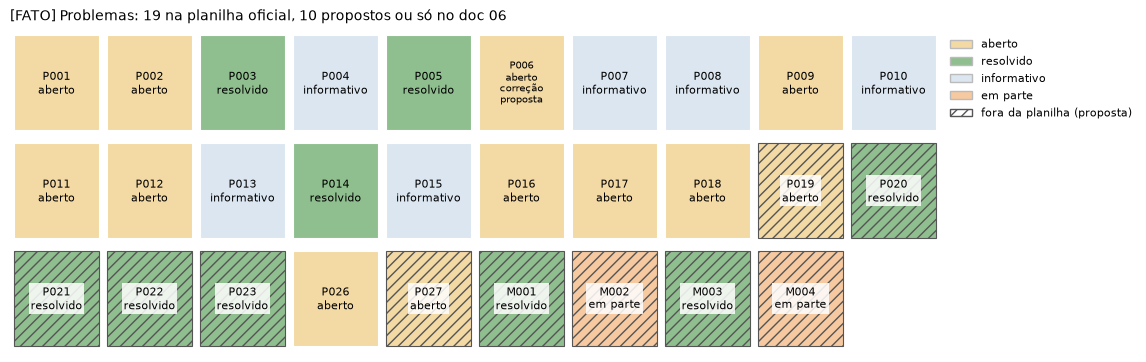

In [4]:
p = t["problemas"]
notas = ["correção proposta" if c else "" for c in p["correcao_proposta"]]
fig, ax = plt.subplots(figsize=(12, 4.2))
D.grade_estados(ax, p["id"], p["estado"], colunas=10, hachurar=p["na_planilha"].eq("não"), notas=notas, tamanho=8)
na = int(p["na_planilha"].eq("sim").sum())
F.titulo(ax, f"Problemas: {na} na planilha oficial, {len(p) - na} propostos ou só no doc 06", "FATO")
F.salvar(fig, FIGURAS, "06_problemas")
plt.show()

In [5]:
planilha = t["planilha"].set_index("id")
extras = t["extras"].set_index("id")
tab = p.set_index("id")[["tipo", "objeto", "estado", "na_planilha", "correcao_proposta"]].copy()
tab["descricao"] = [planilha.loc[i, "descricao"] if i in planilha.index else extras.loc[i, "descricao"] for i in tab.index]
tab["descricao"] = tab["descricao"].str.slice(0, 180)
tab

,tipo,objeto,estado,na_planilha,correcao_proposta,descricao
id,,,,,,
P001,ruptura_de_esquema,IN_MED / IN_COMUM_MEDIO_*,aberto,sim,,Coluna IN_MED (oferta de EM) foi removida em 2025 e substituída por família IN_COMUM_MEDIO_* com granularidade diferente. IN_MED não discriminava modalidade; as novas colunas separ
P002,ruptura_de_esquema,IN_NOTURNO,aberto,sim,,Coluna IN_NOTURNO removida em 2025; sem substituto direto na tabela Escola. Proxy disponível em Tabela_Turma: QT_TUR_BAS_N (turmas noturnas totais) ou QT_TUR_MED_N (só EM).
P003,ruptura_de_esquema,QT_MAT_* / QT_TUR_* / QT_DOC_* em Escola 2025,resolvido,sim,,Em 2025 as colunas de contagem de matrícula / turma / docente foram removidas da tabela Escola e transferidas para tabelas separadas (Tabela_Matricula / Tabela_Turma / Tabela_Docen
P004,cobertura,Tabela_Turma_2025 vs Tabela_Matricula_2025,informativo,sim,,6 escolas presentes em Turma mas ausentes em Matrícula: CO_ENTIDADE 52091376 52233359 15164187 42164095 42164109 42164176. Todas fora de RR (GO PA SC); 3 privadas.
P005,versionamento,dados/bruto/brutos-inep/TDI_2025_MUNICIPIOS (1).zip,resolvido,sim,,Download duplicado: o mesmo arquivo existe com sufixo ' (1)'. Conteúdo bit-a-bit idêntico ao original.
P006,cobertura,"dados/bruto/brutos-inep/ (séries ATU, HAD, IED, TDI, tx_rend)",aberto,sim,estado proposto: resolvido,Séries de indicadores do INEP incompletas na pasta: HAD só tem 2025; IED 2019 só nível Brasil/UF e IED 2020 sem nível escola; ATU 2025 sem nível municípios; tx_rend 2025 sem nível
P007,versionamento,"brutos-inep/ATU_2022_{BRASIL_REGIOES_UFS,ESCOLAS,MUNICIPIOS}.zip; TDI_2021_MUNICIPIOS.zip",informativo,sim,,O md5 do .xlsx registrado no md5_*.txt do próprio INEP não confere com o .xlsx dentro do zip; o md5 do .ods confere. Timestamps internos do zip mostram o .xlsx salvo depois do .ods
P008,versionamento,brutos-inep/tx_rend_municipios_2020.zip,informativo,sim,,"O md5_*.txt lista o .ods duas vezes e não traz entrada para o .xlsx; o zip contém também um arquivo de trava do LibreOffice (.~lock.tx_rend_municipios_2020.ods#), indício de que a"
P009,ruptura_de_esquema,"tx_rend (todos os níveis), nomes técnicos das colunas",aberto,sim,,"Os nomes técnicos das taxas de rendimento mudaram em 2021. 2019-2020: 'Ano'/'ano', 'TIPOLOCA', 'Dependad'/'DEPENDAD', tap_* (aprovação), tre_* (reprovação), tab_* (abandono), com e"


**Os abertos que mais pesam:**

- **P026:** a identidade contábil (aprovação + reprovação + abandono = 100) está resolvida no protocolo, mas
  a linha segue aberta na planilha.
- **P017** e **P016:** universo e ATU.
- **P018:** as taxas não têm denominador, e uma escola pequena pesa igual a uma grande.
- **P001**, **P002** e **P012:** os filtros da fase 2.

O **P027** (proposto) registra o uso do desfecho de 2025, mas o texto precisa da correção da divergência 1.

## 8. As perguntas do doc 06 (Q1–Q10)

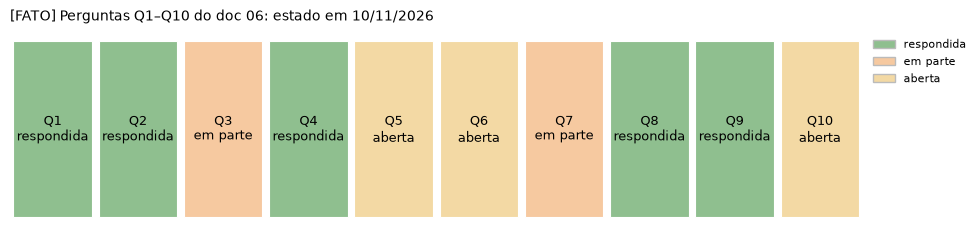

,pergunta,estado,resposta,fonte
id,,,,
Q1,Quem escreve e valida src/base_longitudinal.py? Está definitivo?,respondida,existe desde 30/09 e regera a v1.0 com as mesmas 6.054 linhas (critérios 1–4); mudanças futuras só pelas propostas D8 e P017,CLAUDE.md §8
Q2,A v1.0 do orientador vira base oficial ou fica como referência?,respondida,"fica como referência externa (dados/externo/); a base oficial é a regerada por código, igual a ela",DECISOES.md 2026-09-30
Q3,Qual R² / MAE / Recall@K é 'bom o suficiente'?,em parte,"não há meta de R² nem de MAE; o critério passou a ser superar baselines pré-especificados, com intervalo e Holm (pesquisadora, 02/11; validação do orientador pendente)",DECISOES.md 2026-11-02
Q4,"Pico de 2022: incluir, excluir ou usar como teste?",respondida,"a D6 do orientador mantém 2020–2021 com sensibilidade S1–S4; 2022 não é pico no AF (síntese §4, nº 2); as S1–S4 não foram rodadas",DECISOES.md D6
Q5,IED 2019–2020 e HAD: no modelo ou só na análise?,aberta,baixados e fora do painel (P019); decisão com o orientador,CLAUDE.md §6
Q6,Prazos do PIBIC e do artigo,aberta,não registrados em nenhum documento do projeto,—
Q7,Divisão de trabalho nas próximas fases,em parte,"de fato: o Gustavo construiu o gustavo/ (07–14/10) e a pesquisadora, a base oficial e a avaliação (desde 02/11); nada decidido para a escrita",git log dos dois repositórios
Q8,Variáveis do fundamental no modelo de EM?,respondida,"não: cada modelo só vê a sua etapa (doc 06, D15)",síntese §6.1
Q9,Infraestrutura do Censo no modelo ou só como caracterização?,respondida,"testada no bloco 4, sem sinal (0 de 8 na F1); sai do modelo e fica como estratificação",DECISOES.md 2026-11-02


In [6]:
q = t["perguntas"]
fig, ax = plt.subplots(figsize=(11, 2.6))
D.grade_estados(ax, q["id"], q["estado"], colunas=10, tamanho=9)
F.titulo(ax, "Perguntas Q1–Q10 do doc 06: estado em 10/11/2026", "FATO")
F.salvar(fig, FIGURAS, "06_perguntas")
plt.show()
q.set_index("id")[["pergunta", "estado", "resposta", "fonte"]]

## 9. Perguntas novas

Não estavam no doc 06. Cada uma depende de alguém responder; aqui não há resposta, só a pergunta e onde ela
nasceu.

| # | Pergunta | Para quem | De onde vem |
|---|---|---|---|
| N1 | O orientador valida a mudança de objetivo e as regras de 02/11 (Cenário B, B1R_lag, Holm, K)? | orientador | `DECISOES.md` (falha de processo); síntese, "O que não ficou registrado", nº 7 |
| N2 | O teste final continua sendo 2024→2025, declarando que já foi usado, ou passa a ser prospectivo (2025→2026, previsões seladas antes de o INEP publicar)? | orientador | divergência 1; Plano avançado, decisões 1 e 2 |
| N3 | Como ganhar poder estatístico: mais transições (D11), *group k-fold* por escola, outro desenho de avaliação? | orientador e pesquisadora | notebook 03 (largura ~0,30); síntese §5.1 |
| N4 | O desfecho principal continua a taxa, ou entra a contagem de abandonos (peso por matrícula, P018)? | orientador | metodologia E9; Plano avançado, decisão 4 |
| N5 | Quais são os prazos do PIBIC e do artigo? (Q6, ainda sem registro) | grupo | doc 06 |
| N6 | Quem escreve o quê? (Q7) | grupo | doc 06 |

## 10. Todas as entradas do `DECISOES.md`

Em ordem de data, para consulta. A linha do tempo está no notebook 00, §5.

In [7]:
t["tempo"][["data", "categoria", "titulo"]].set_index("data")

,categoria,titulo
data,,
2026-09-09,dados e procedência,Encoding de todos os arquivos brutos
2026-09-09,dados e procedência,Separador dos arquivos brutos
2026-09-09,dados e procedência,Granularidade das tabelas Turma/Matrícula/Docente 2025
2026-09-09,dados e procedência,Proxy para IN_NOTURNO em 2025
2026-09-09,dados e procedência,"Definição de ""oferta de ensino médio"" entre gerações"
2026-09-15,dados e procedência,Organização dos arquivos de dados/bruto/brutos-inep/ (SUBSTITUÍDA pela entrada seguinte)
2026-09-15,dados e procedência,Extração dos .zip de indicadores (substitui a cópia organizada)
2026-09-15,dados e procedência,Leitura das planilhas de indicadores: linha de nomes técnicos é detectada
2026-09-15,dados e procedência,Microdados 2019–2021 entram no dicionário ARQUIVOS
